<a href="https://colab.research.google.com/github/NOWSHIDHAKI/Brain-Tumor-Predection/blob/main/Brain_Tumor_Big_Data_Analytics_UPDATED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Brain Tumor Classification using Vision Transformer (ViT)

Classifies brain MRI scans into **4 categories**:
| Class | Tumor? | Severity |
|---|---|---|
| Glioma | ✅ Yes | 🔴 High |
| Meningioma | ✅ Yes | 🟡 Moderate |
| Pituitary | ✅ Yes | 🟡 Moderate |
| No Tumor | ❌ No | ✅ Normal |

---
### ⚡ FIRST — Enable GPU:
> **Runtime → Change runtime type → T4 GPU → Save → Connect**

---
> ⚠️ *Disclaimer: AI-assisted only. Always consult a qualified medical professional.*

## 📦 Cell 1 — Install Libraries

In [7]:
!pip install timm opencv-python-headless scikit-learn seaborn -q
print('✅ Libraries installed!')

✅ Libraries installed!


## 📂 Cell 2 — Download Dataset via Kaggle API

### How to get your `kaggle.json`:
1. Go to 👉 [https://www.kaggle.com](https://www.kaggle.com) and log in
2. Click your **profile picture** → **Settings**
3. Scroll to **API** section → Click **'Create New Token'**
4. A file called `kaggle.json` will download to your PC
5. Run this cell → click **Choose Files** → upload that `kaggle.json`

> ✅ This is much faster than uploading the full zip!

In [8]:
# Download dataset securely using Google Colab Secrets.
# Before running:
# 1. Revoke any Kaggle token previously exposed in a notebook.
# 2. In Colab, open the Secrets (key) panel.
# 3. Add a secret named KAGGLE_API_TOKEN with your NEW Kaggle API token.
# 4. Enable notebook access for this secret.

!pip install kagglehub -q

from google.colab import userdata
import os
import kagglehub

kaggle_token = userdata.get("KAGGLE_API_TOKEN")
if not kaggle_token:
    raise ValueError(
        "KAGGLE_API_TOKEN not found. Add it in Colab Secrets and enable notebook access."
    )

os.environ["KAGGLE_API_TOKEN"] = kaggle_token

print("Downloading Brain Tumor MRI Dataset...")
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Downloaded to:", path)

TRAIN_DIR = None
TEST_DIR = None

for root, dirs, _ in os.walk(path):
    if "Training" in dirs and "Testing" in dirs:
        TRAIN_DIR = os.path.join(root, "Training")
        TEST_DIR = os.path.join(root, "Testing")
        break

if TRAIN_DIR is None or TEST_DIR is None:
    raise FileNotFoundError("Could not locate Training and Testing folders.")

print("Training:", TRAIN_DIR)
print("Testing :", TEST_DIR)
print("Classes :", sorted(os.listdir(TRAIN_DIR)))


Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Downloaded to: /kaggle/input/brain-tumor-mri-dataset
Training: /kaggle/input/brain-tumor-mri-dataset/Training
Testing : /kaggle/input/brain-tumor-mri-dataset/Testing
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


## ⚙️ Cell 3 — Imports, Config & Class Info

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import timm
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from PIL import Image
import cv2
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from tqdm.notebook import tqdm
import warnings, os
warnings.filterwarnings('ignore')

# ── GPU Check ───────────────────────────────────────────────
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'🖥️  Device : {device.upper()}')
if device == 'cuda':
    print(f'   GPU    : {torch.cuda.get_device_name(0)}')
    print(f'   Memory : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    print('   ⚠️  No GPU! Go to Runtime → Change runtime type → T4 GPU')

# ── Config ──────────────────────────────────────────────────
CONFIG = {
    'train_dir'   : TRAIN_DIR,
    'test_dir'    : TEST_DIR,
    'model_name'  : 'vit_base_patch16_224',
    'num_classes' : 4,
    'img_size'    : 224,
    'batch_size'  : 32,
    'epochs'      : 15,
    'lr'          : 2e-4,
    'weight_decay': 1e-5,
    'save_path'   : 'brain_tumor_vit_best.pth',
    'num_workers' : 2,
    'device'      : device,
}

CLASS_NAMES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

CLASS_INFO = {
    'Glioma': {
        'emoji'        : '🔴',
        'tumor'        : True,
        'brain_region' : 'Cerebrum / Brainstem / Cerebellum',
        'description'  : 'Tumor from glial cells of the brain/spinal cord. Affects thinking, movement, and bodily functions.',
        'affected_part': 'CEREBRUM (thought, memory, movement), BRAINSTEM (breathing, heart rate), or CEREBELLUM (balance).',
        'severity'     : 'HIGH ⚠️  — Can be malignant (cancerous)',
        'cure_chance'  : {
            'label'  : 'Moderate to Low',
            'percent': '30–60%',
            'details': 'Grade I–II: 60–80% 5-yr survival.\nGrade III: ~30–40%.\nGrade IV (GBM): ~5–10%.\nEarly detection improves outcomes significantly.'
        },
        'treatments': ['Surgical resection', 'Radiation therapy', 'Chemotherapy (Temozolomide)', 'Immunotherapy', 'Tumor Treating Fields (TTFields)'],
    },
    'Meningioma': {
        'emoji'        : '🟡',
        'tumor'        : True,
        'brain_region' : 'Brain Surface / Skull Base / Spinal Cord Covering',
        'description'  : 'Tumor from the meninges — membranes covering the brain. Usually benign and slow-growing.',
        'affected_part': 'OUTER BRAIN SURFACE or SKULL BASE. Presses on nearby regions causing headaches, vision issues, or weakness.',
        'severity'     : 'MODERATE 🟡 — Usually benign; malignant in ~3% of cases',
        'cure_chance'  : {
            'label'  : 'High',
            'percent': '70–90%',
            'details': 'Grade I (Benign): 90%+ survival with surgery.\nGrade II: 50–70% recurrence-free at 5 yrs.\nGrade III: ~50% 5-yr survival.'
        },
        'treatments': ['Active surveillance', 'Surgical resection', 'Gamma Knife / CyberKnife', 'Radiation therapy', 'Symptom medications'],
    },
    'No Tumor': {
        'emoji'        : '✅',
        'tumor'        : False,
        'brain_region' : 'N/A — All regions appear normal',
        'description'  : 'No tumor or abnormality detected. Brain structure is within normal limits.',
        'affected_part': 'No affected region. CEREBRUM, CEREBELLUM, BRAINSTEM — all appear structurally normal.',
        'severity'     : 'NORMAL ✅ — No pathology detected',
        'cure_chance'  : {
            'label'  : 'N/A',
            'percent': '100%',
            'details': 'No tumor detected. No treatment required.'
        },
        'treatments': ['No tumor-specific treatment needed', 'Routine annual MRI monitoring', 'Regular health check-ups'],
    },
    'Pituitary': {
        'emoji'        : '🟡',
        'tumor'        : True,
        'brain_region' : 'Pituitary Gland — Base of Brain (Sella Turcica)',
        'description'  : "Tumor of the pituitary gland — the body's master hormone gland. Usually benign.",
        'affected_part': 'PITUITARY GLAND (sella turcica). May press on OPTIC CHIASM (vision) or HYPOTHALAMUS (body regulation).',
        'severity'     : 'MODERATE 🟡 — Usually benign; significant hormonal effects',
        'cure_chance'  : {
            'label'  : 'High',
            'percent': '75–95%',
            'details': 'Microadenomas (<10mm): 85–95% cure with surgery.\nMacroadenomas: 50–70%.\nProlactinomas: 70–80% controlled with medication alone.'
        },
        'treatments': ['Dopamine agonists (Cabergoline)', 'Transsphenoidal surgery', 'Gamma Knife radiosurgery', 'Hormone replacement', 'MRI monitoring'],
    },
}

print('\n✅ Config and class info ready!')

🖥️  Device : CUDA
   GPU    : Tesla T4
   Memory : 15.6 GB

✅ Config and class info ready!


# 🚀 Big Data Analytics Upgrade — Phase 1: Environment Setup

This phase adds Apache Spark / PySpark and Parquet storage alongside the existing Vision Transformer (ViT) model. The original ViT architecture and training workflow are preserved.

**Colab note:** `local[*]` runs Spark on this Colab runtime. It is a Spark-based prototype, not a multi-node Hadoop cluster.

In [10]:
# PHASE 1 — CELL 1: Install Big Data libraries
!pip install pyspark==3.5.1 pyarrow -q
print('PySpark and PyArrow installed successfully!')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.
PySpark and PyArrow installed successfully!


In [11]:
# PHASE 1 — CELL 2: Import Big Data libraries
import os
import sys
import pandas as pd
import numpy as np

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType,
    LongType, DoubleType
)

print('Big Data libraries imported successfully!')

Big Data libraries imported successfully!


In [12]:
# PHASE 1 — CELL 3: Initialize Apache Spark
spark = (
    SparkSession.builder
    .master('local[*]')
    .appName('BrainTumorBigDataAnalytics')
    .config('spark.sql.shuffle.partitions', '8')
    .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
    .getOrCreate()
)

print('Apache Spark initialized successfully!')
print('Spark Version:', spark.version)
print('Application Name:', spark.sparkContext.appName)
print('Master:', spark.sparkContext.master)

Apache Spark initialized successfully!
Spark Version: 3.5.1
Application Name: BrainTumorBigDataAnalytics
Master: local[*]


In [13]:
# PHASE 1 — CELL 4: Verify Spark DataFrame execution
test_data = [
    ('Glioma', 100),
    ('Meningioma', 150),
    ('No Tumor', 200),
    ('Pituitary', 120)
]

test_df = spark.createDataFrame(test_data, ['Tumor_Type', 'Image_Count'])
test_df.show()
print('Total records:', test_df.count())

+----------+-----------+
|Tumor_Type|Image_Count|
+----------+-----------+
|    Glioma|        100|
|Meningioma|        150|
|  No Tumor|        200|
| Pituitary|        120|
+----------+-----------+

Total records: 4


In [14]:
# PHASE 1 — CELL 5: Configure project and Parquet directories
BASE_DIR = '/content/brain_tumor_big_data'
RAW_DIR = os.path.join(BASE_DIR, 'raw')
PROCESSED_DIR = os.path.join(BASE_DIR, 'processed')
PARQUET_DIR = os.path.join(PROCESSED_DIR, 'parquet')
REPORT_DIR = os.path.join(BASE_DIR, 'reports')

for directory in [RAW_DIR, PROCESSED_DIR, PARQUET_DIR, REPORT_DIR]:
    os.makedirs(directory, exist_ok=True)

print('Project directories created!')
print('Base directory:', BASE_DIR)
print('Parquet storage:', PARQUET_DIR)

Project directories created!
Base directory: /content/brain_tumor_big_data
Parquet storage: /content/brain_tumor_big_data/processed/parquet


In [15]:
# PHASE 1 — CELL 6: Verify the original MRI dataset paths
# TRAIN_DIR and TEST_DIR are created by the existing Kaggle download cell.
assert os.path.isdir(TRAIN_DIR), f'Training directory not found: {TRAIN_DIR}'
assert os.path.isdir(TEST_DIR), f'Testing directory not found: {TEST_DIR}'

print('Training directory:', TRAIN_DIR)
print('Testing directory :', TEST_DIR)
print('Training classes:')
for class_name in sorted(os.listdir(TRAIN_DIR)):
    class_path = os.path.join(TRAIN_DIR, class_name)
    if os.path.isdir(class_path):
        print('-', class_name)

Training directory: /kaggle/input/brain-tumor-mri-dataset/Training
Testing directory : /kaggle/input/brain-tumor-mri-dataset/Testing
Training classes:
- glioma
- meningioma
- notumor
- pituitary


In [16]:
# PHASE 1 — CELL 7: Test Parquet write and read
test_output = os.path.join(PARQUET_DIR, 'spark_test')

test_df.write.mode('overwrite').parquet(test_output)
loaded_df = spark.read.parquet(test_output)

print('Parquet data saved and loaded successfully!')
loaded_df.show()
print('Records retrieved:', loaded_df.count())

Parquet data saved and loaded successfully!
+----------+-----------+
|Tumor_Type|Image_Count|
+----------+-----------+
|  No Tumor|        200|
| Pituitary|        120|
|    Glioma|        100|
|Meningioma|        150|
+----------+-----------+

Records retrieved: 4


## ✅ Phase 1 checkpoint

Phase 1 is complete when all seven cells run successfully. Continue to Phase 2 to build the MRI image metadata ingestion pipeline, perform data-quality checks, and write the resulting metadata to Parquet.

## 🖼️ Cell 4 — Dataset Loaders & Sample Preview

📊 Training samples : 5600
📊 Testing  samples : 1600
📁 Classes detected : ['glioma', 'meningioma', 'notumor', 'pituitary']


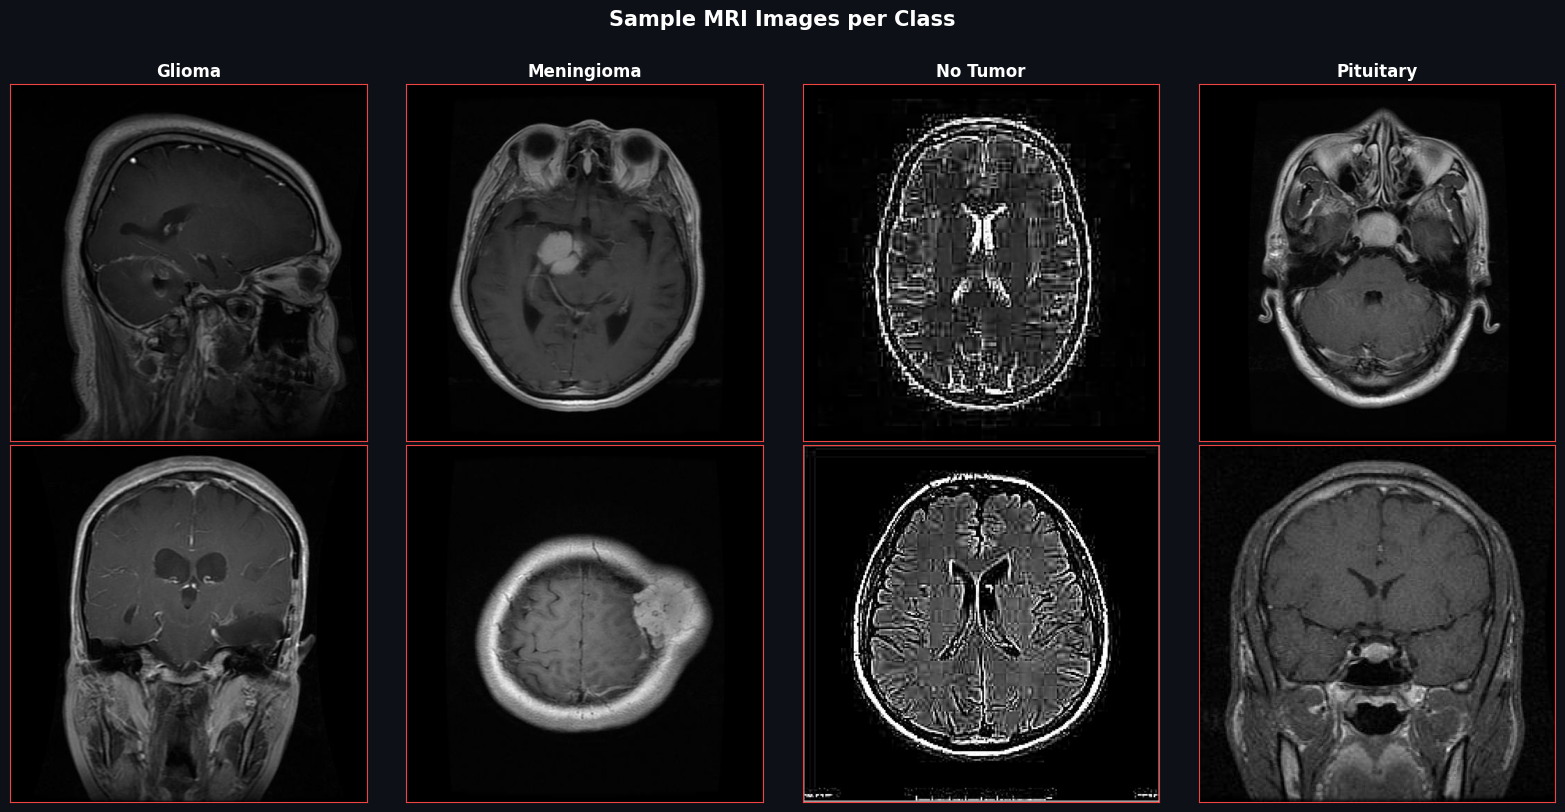

In [17]:
def get_transforms():
    train_tf = transforms.Compose([
        transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(p=0.1),
        transforms.RandomRotation(20),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.1),
        transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    val_tf = transforms.Compose([
        transforms.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    return train_tf, val_tf

train_tf, val_tf = get_transforms()
train_ds = datasets.ImageFolder(CONFIG['train_dir'], transform=train_tf)
test_ds  = datasets.ImageFolder(CONFIG['test_dir'],  transform=val_tf)

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                          shuffle=True,  num_workers=CONFIG['num_workers'], pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True)

print(f'📊 Training samples : {len(train_ds)}')
print(f'📊 Testing  samples : {len(test_ds)}')
print(f'📁 Classes detected : {train_ds.classes}')

# ── Sample Preview ───────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.patch.set_facecolor('#0d1117')
fig.suptitle('Sample MRI Images per Class', fontsize=15, fontweight='bold', color='white', y=1.01)
for i, cls in enumerate(train_ds.classes):
    cls_dir = os.path.join(CONFIG['train_dir'], cls)
    imgs    = os.listdir(cls_dir)
    for row, idx in enumerate([0, 5]):
        img = Image.open(os.path.join(cls_dir, imgs[idx])).convert('RGB')
        axes[row][i].imshow(img)
        axes[row][i].set_facecolor('#161b22')
        for sp in axes[row][i].spines.values(): sp.set_color('#ef4444')
        axes[row][i].set_xticks([]); axes[row][i].set_yticks([])
        if row == 0:
            axes[row][i].set_title(CLASS_NAMES[i], fontsize=12, fontweight='bold', color='white')
plt.tight_layout()
plt.show()

## 🤖 Cell 5 — Vision Transformer Model

In [18]:
class BrainTumorViT(nn.Module):
    def __init__(self, num_classes=4, pretrained=True):
        super().__init__()
        self.vit = timm.create_model(
            CONFIG['model_name'], pretrained=pretrained, num_classes=0
        )
        in_features = self.vit.num_features
        self.classifier = nn.Sequential(
            nn.LayerNorm(in_features),
            nn.Dropout(0.3),
            nn.Linear(in_features, 512),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.vit(x))

model = BrainTumorViT(num_classes=CONFIG['num_classes']).to(CONFIG['device'])
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'🧠 Model         : {CONFIG["model_name"]}')
print(f'   Total params  : {total:,}')
print(f'   Trainable     : {trainable:,}')
print(f'   Device        : {CONFIG["device"].upper()}')
print('✅ Model ready!')

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

🧠 Model         : vit_base_patch16_224
   Total params  : 86,195,972
   Trainable     : 86,195,972
   Device        : CUDA
✅ Model ready!


## 🚀 Cell 6 — Train the Model
> ⏱️ ~20–30 minutes on T4 GPU

In [19]:
import time

def train_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    total_loss = correct = total = 0
    for images, labels in tqdm(loader, desc='  Training', leave=False):
        images, labels = images.to(CONFIG['device']), labels.to(CONFIG['device'])
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=(CONFIG['device'] == 'cuda')):
            out  = model(images)
            loss = criterion(out, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        correct    += out.argmax(1).eq(labels).sum().item()
        total      += labels.size(0)
    return total_loss / len(loader), 100.0 * correct / total


def validate(model, loader, criterion):
    model.eval()
    total_loss = correct = total = 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc='  Validating', leave=False):
            images, labels = images.to(CONFIG['device']), labels.to(CONFIG['device'])
            out  = model(images)
            loss = criterion(out, labels)
            total_loss += loss.item()
            preds = out.argmax(1)
            correct    += preds.eq(labels).sum().item()
            total      += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return total_loss / len(loader), 100.0 * correct / total, all_preds, all_labels


optimizer = optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=CONFIG['lr'],
    steps_per_epoch=len(train_loader),
    epochs=CONFIG['epochs'], pct_start=0.1
)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler    = torch.cuda.amp.GradScaler(enabled=(CONFIG['device'] == 'cuda'))

history      = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_acc     = 0.0
final_preds  = []
final_labels = []
train_start  = time.time()

print('🚀 Training started...\n')
for epoch in range(CONFIG['epochs']):
    ep_start = time.time()
    print(f'Epoch [{epoch+1:02d}/{CONFIG["epochs"]}]')
    tr_loss, tr_acc                = train_epoch(model, train_loader, optimizer, criterion, scaler)
    vl_loss, vl_acc, preds, labels = validate(model, test_loader, criterion)
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    ep_mins   = (time.time() - ep_start) / 60
    elapsed   = (time.time() - train_start) / 60
    remaining = ep_mins * (CONFIG['epochs'] - epoch - 1)

    print(f'  Train → Loss: {tr_loss:.4f} | Acc: {tr_acc:.2f}%')
    print(f'  Val   → Loss: {vl_loss:.4f} | Acc: {vl_acc:.2f}%')
    print(f'  ⏱  Epoch: {ep_mins:.1f} min | Elapsed: {elapsed:.1f} min | ETA: ~{remaining:.0f} min')

    if vl_acc > best_acc:
        best_acc     = vl_acc
        final_preds  = preds
        final_labels = labels
        torch.save({'model_state_dict': model.state_dict(),
                    'val_acc': vl_acc, 'epoch': epoch}, CONFIG['save_path'])
        print(f'  💾 Best model saved! (Val Acc: {best_acc:.2f}%)')
    print()

total_mins = (time.time() - train_start) / 60
print(f'🎉 Training Complete!  Best Val Acc: {best_acc:.2f}%')
print(f'⏱  Total time: {total_mins:.1f} minutes')

🚀 Training started...

Epoch [01/15]


  Training:   0%|          | 0/175 [00:00<?, ?it/s]

  Validating:   0%|          | 0/50 [00:00<?, ?it/s]

  Train → Loss: 0.7163 | Acc: 82.02%
  Val   → Loss: 0.5522 | Acc: 91.00%
  ⏱  Epoch: 1.5 min | Elapsed: 1.5 min | ETA: ~21 min
  💾 Best model saved! (Val Acc: 91.00%)

Epoch [02/15]


  Training:   0%|          | 0/175 [00:00<?, ?it/s]

  Validating:   0%|          | 0/50 [00:00<?, ?it/s]

... (36 outputs left out)

  Train → Loss: 0.3627 | Acc: 99.45%
  Val   → Loss: 0.4758 | Acc: 95.44%
  ⏱  Epoch: 1.3 min | Elapsed: 18.5 min | ETA: ~1 min

Epoch [15/15]


  Training:   0%|          | 0/175 [00:00<?, ?it/s]

  Validating:   0%|          | 0/50 [00:00<?, ?it/s]

  Train → Loss: 0.3628 | Acc: 99.54%
  Val   → Loss: 0.4987 | Acc: 94.94%
  ⏱  Epoch: 1.3 min | Elapsed: 19.7 min | ETA: ~0 min

🎉 Training Complete!  Best Val Acc: 95.94%
⏱  Total time: 19.7 minutes


## 📊 Cell 7 — Training Curves & Confusion Matrix

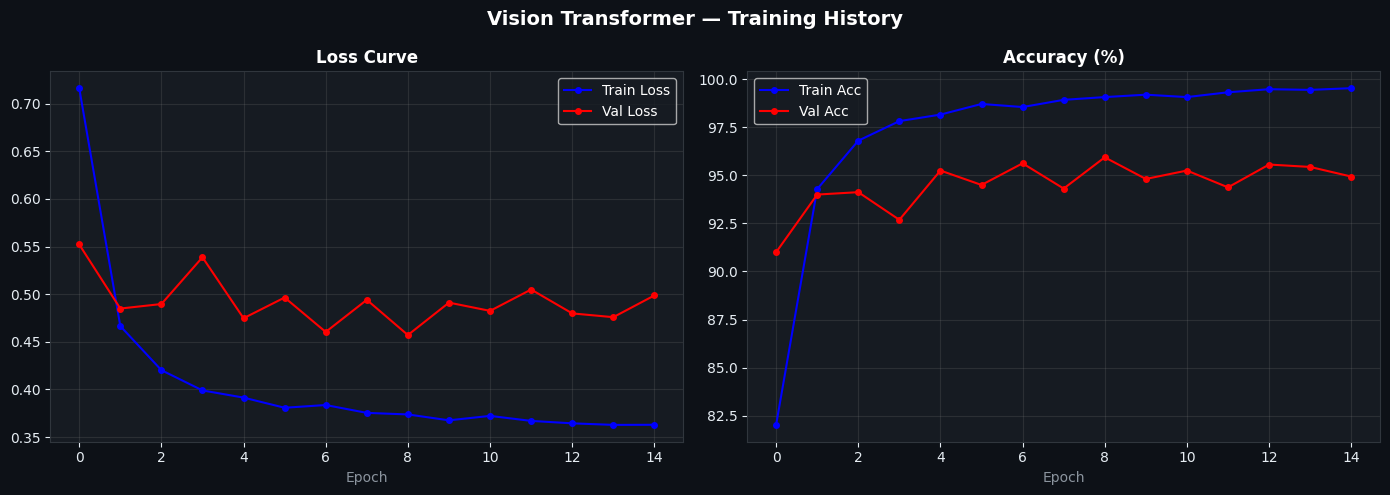

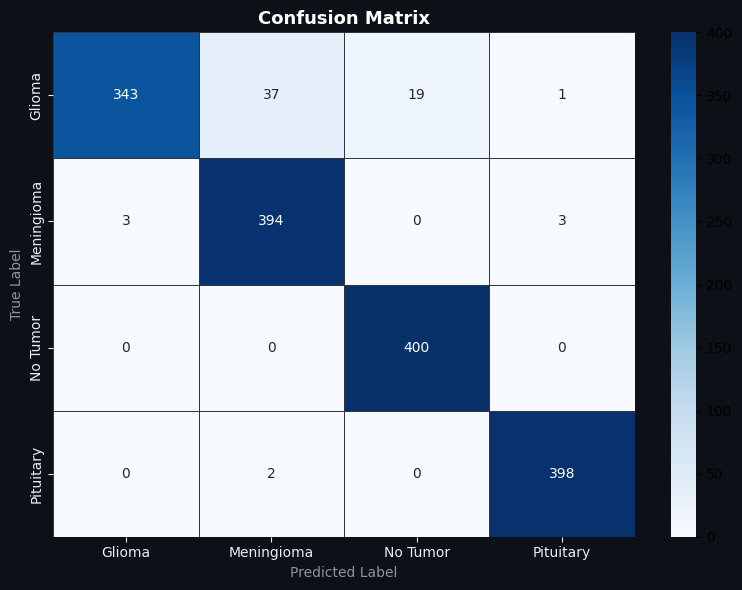


📋 Classification Report:
              precision    recall  f1-score   support

      Glioma       0.99      0.86      0.92       400
  Meningioma       0.91      0.98      0.95       400
    No Tumor       0.95      1.00      0.98       400
   Pituitary       0.99      0.99      0.99       400

    accuracy                           0.96      1600
   macro avg       0.96      0.96      0.96      1600
weighted avg       0.96      0.96      0.96      1600



In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0d1117')
fig.suptitle('Vision Transformer — Training History', fontsize=14, fontweight='bold', color='white')
for ax in axes:
    ax.set_facecolor('#161b22')
    for sp in ax.spines.values(): sp.set_color('#30363d')
    ax.tick_params(colors='#e6edf3')
axes[0].plot(history['train_loss'], 'b-o', label='Train Loss', markersize=4)
axes[0].plot(history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Loss Curve', color='white', fontweight='bold')
axes[0].set_xlabel('Epoch', color='#8b949e')
axes[0].legend(facecolor='#161b22', labelcolor='white')
axes[0].grid(True, alpha=0.2, color='gray')
axes[1].plot(history['train_acc'], 'b-o', label='Train Acc', markersize=4)
axes[1].plot(history['val_acc'],   'r-o', label='Val Acc',   markersize=4)
axes[1].set_title('Accuracy (%)', color='white', fontweight='bold')
axes[1].set_xlabel('Epoch', color='#8b949e')
axes[1].legend(facecolor='#161b22', labelcolor='white')
axes[1].grid(True, alpha=0.2, color='gray')
plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

cm = confusion_matrix(final_labels, final_preds)
plt.figure(figsize=(8, 6), facecolor='#0d1117')
ax = plt.gca(); ax.set_facecolor('#161b22')
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='#30363d')
plt.title('Confusion Matrix', fontsize=13, fontweight='bold', color='white')
plt.ylabel('True Label', color='#8b949e')
plt.xlabel('Predicted Label', color='#8b949e')
plt.tick_params(colors='#e6edf3')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

print('\n📋 Classification Report:')
print(classification_report(final_labels, final_preds, target_names=CLASS_NAMES))

## 🔥 Cell 8 — GradCAM Setup

In [21]:
class GradCAMViT:
    def __init__(self, model):
        self.model       = model
        self.gradients   = None
        self.activations = None
        target = model.vit.blocks[-1].norm1
        target.register_forward_hook(self._fwd)
        target.register_full_backward_hook(self._bwd)

    def _fwd(self, m, inp, out): self.activations = out
    def _bwd(self, m, gi,  go):  self.gradients   = go[0]

    def generate(self, img_tensor, cls_idx=None):
        self.model.eval()
        t   = img_tensor.clone().requires_grad_(True)
        out = self.model(t)
        if cls_idx is None:
            cls_idx = out.argmax(1).item()
        self.model.zero_grad()
        one_hot = torch.zeros_like(out)
        one_hot[0][cls_idx] = 1
        out.backward(gradient=one_hot)
        weights = self.gradients.mean(dim=[0, 2])
        cam     = (weights.unsqueeze(-1) * self.activations[0]).sum(1)
        cam     = cam[1:].detach().cpu().numpy()
        n       = int(len(cam) ** 0.5)
        cam     = cam.reshape(n, n)
        cam     = np.maximum(cam, 0)
        cam     = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam     = cv2.resize(cam, (224, 224))
        return cam, cls_idx

print('✅ GradCAM ready!')

✅ GradCAM ready!


## 🔬 Cell 9 — Upload Brain MRI & Get Full Report
**Run → Upload any brain MRI image → Get full diagnosis with heatmap!**

Training dataset: /kaggle/input/brain-tumor-mri-dataset/Training
Testing dataset : /kaggle/input/brain-tumor-mri-dataset/Testing
✅ Trained model loaded. Validation accuracy: 95.94%
📤 Upload a brain MRI image (JPG / PNG):


Saving images.jpg to images.jpg


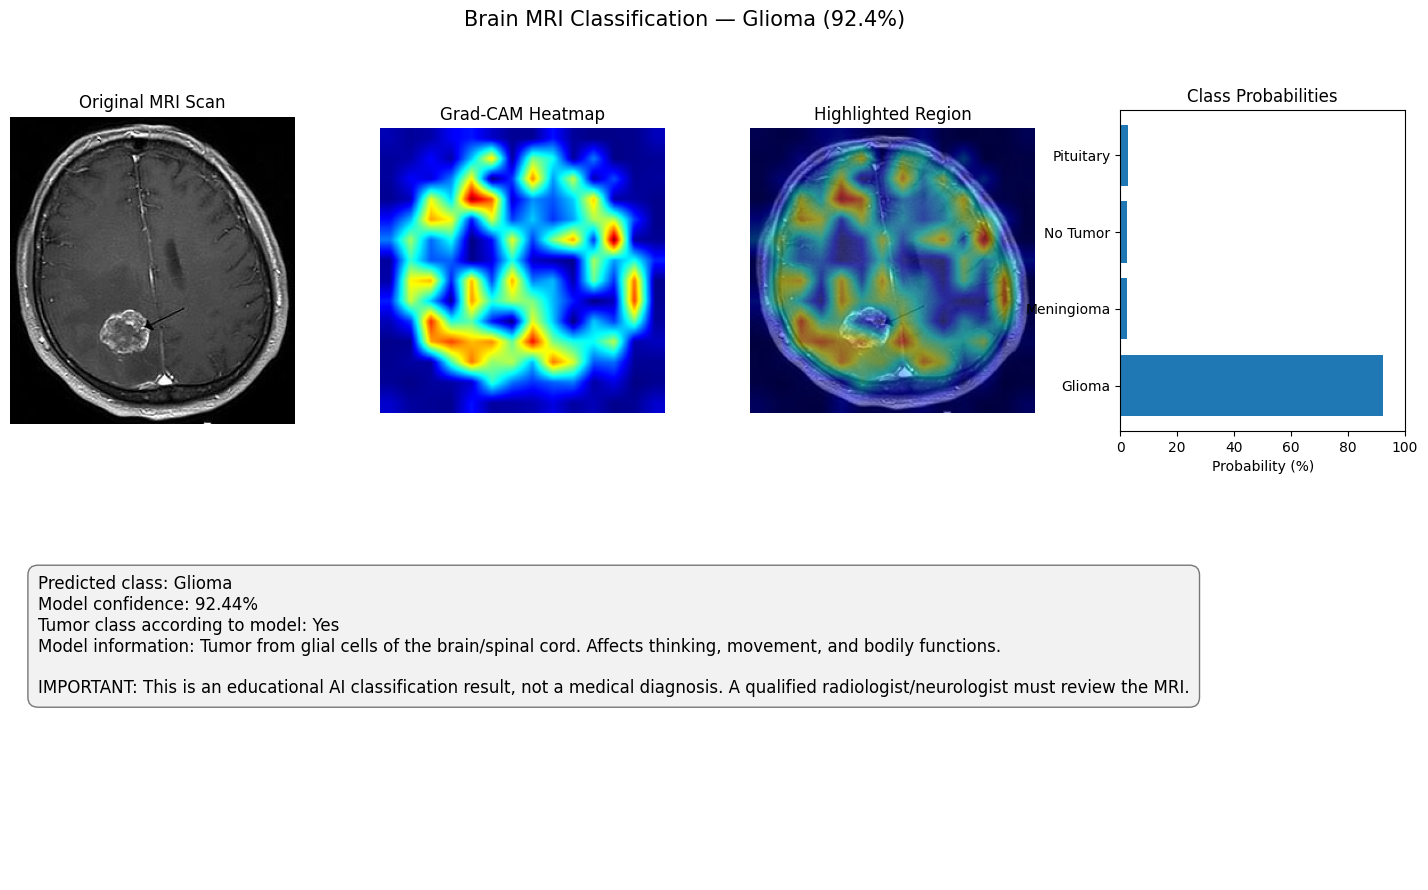


BRAIN MRI CLASSIFICATION RESULT
Prediction : Glioma
Confidence : 92.44%

Class probabilities:
  Glioma         :  92.44%
  Meningioma     :   2.29%
  No Tumor       :   2.44%
  Pituitary      :   2.83%
Educational use only — not a medical diagnosis.


In [26]:
# FINAL PREDICTION CELL — Run this only AFTER the ViT training cell has completed.
# Important: This cell reuses TRAIN_DIR, TEST_DIR, CONFIG, model, CLASS_NAMES,
# CLASS_INFO, val_tf and GradCAMViT created earlier. Do not redefine them here.

from google.colab import files as colab_files
import os
import torch
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Confirm that the dataset paths still point to the folders downloaded earlier.
print("Training dataset:", TRAIN_DIR)
print("Testing dataset :", TEST_DIR)
assert os.path.isdir(TRAIN_DIR), f"Training folder not found: {TRAIN_DIR}"
assert os.path.isdir(TEST_DIR), f"Testing folder not found: {TEST_DIR}"

# Look for the trained checkpoint in the current Colab directory first,
# then in the optional Google Drive backup location.
checkpoint_path = CONFIG["save_path"]
drive_checkpoint = "/content/drive/MyDrive/BrainTumorViT/brain_tumor_vit_best.pth"

if not os.path.isfile(checkpoint_path) and os.path.isfile(drive_checkpoint):
    checkpoint_path = drive_checkpoint

if not os.path.isfile(checkpoint_path):
    raise FileNotFoundError(
        f"Trained checkpoint not found: {CONFIG['save_path']}\n\n"
        "What to do:\n"
        "1. Run the ViT training cell (the cell that prints 'Training started').\n"
        "2. Wait until training finishes and prints 'Best model saved'.\n"
        "3. Then run this prediction cell again.\n"
        "If you trained in an earlier Colab session, mount Google Drive and "
        "place the checkpoint at /content/drive/MyDrive/BrainTumorViT/brain_tumor_vit_best.pth."
    )

# Load the saved fine-tuned weights into the existing model.
try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=CONFIG["device"],
        weights_only=False
    )
except TypeError:
    # Compatibility with older PyTorch versions that do not accept weights_only.
    checkpoint = torch.load(checkpoint_path, map_location=CONFIG["device"])

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

saved_val_acc = checkpoint.get("val_acc", None)
if saved_val_acc is not None:
    print(f"✅ Trained model loaded. Validation accuracy: {saved_val_acc:.2f}%")
else:
    print("✅ Trained model loaded.")

def predict_image():
    print("📤 Upload a brain MRI image (JPG / PNG):")
    uploaded = colab_files.upload()
    if not uploaded:
        print("❌ No file uploaded.")
        return

    img_path = list(uploaded.keys())[0]
    img_pil = Image.open(img_path).convert("RGB")
    img_tensor = val_tf(img_pil).unsqueeze(0).to(CONFIG["device"])

    with torch.no_grad():
        logits = model(img_tensor)
        probs = torch.softmax(logits, dim=1)[0]

    pred_idx = probs.argmax().item()
    pred_class = CLASS_NAMES[pred_idx]
    confidence = probs[pred_idx].item()
    info = CLASS_INFO[pred_class]
    is_tumor = info["tumor"]

    # Generate Grad-CAM using the GradCAMViT class defined in the earlier cell.
    gradcam = GradCAMViT(model)
    heatmap, _ = gradcam.generate(img_tensor.clone(), pred_idx)

    img_224 = np.array(img_pil.resize((224, 224)))
    heatmap_color = cv2.applyColorMap(
        np.uint8(255 * heatmap), cv2.COLORMAP_JET
    )
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(img_224, 0.55, heatmap_color, 0.45, 0)

    fig = plt.figure(figsize=(18, 10))
    gs = GridSpec(2, 4, figure=fig, hspace=0.4, wspace=0.3)

    ax1 = fig.add_subplot(gs[0, 0])
    ax1.set_title("Original MRI Scan")
    ax1.imshow(img_pil)
    ax1.axis("off")

    ax2 = fig.add_subplot(gs[0, 1])
    ax2.set_title("Grad-CAM Heatmap")
    ax2.imshow(heatmap_color)
    ax2.axis("off")

    ax3 = fig.add_subplot(gs[0, 2])
    ax3.set_title("Highlighted Region")
    ax3.imshow(overlay)
    ax3.axis("off")

    ax4 = fig.add_subplot(gs[0, 3])
    ax4.set_title("Class Probabilities")
    ax4.barh(CLASS_NAMES, [probs[i].item() * 100 for i in range(len(CLASS_NAMES))])
    ax4.set_xlim(0, 100)
    ax4.set_xlabel("Probability (%)")

    ax5 = fig.add_subplot(gs[1, :])
    ax5.axis("off")
    report = (
        f"Predicted class: {pred_class}\n"
        f"Model confidence: {confidence * 100:.2f}%\n"
        f"Tumor class according to model: {'Yes' if is_tumor else 'No'}\n"
        f"Model information: {info['description']}\n\n"
        "IMPORTANT: This is an educational AI classification result, not a medical diagnosis. "
        "A qualified radiologist/neurologist must review the MRI."
    )
    ax5.text(
        0.02, 0.95, report, va="top", ha="left",
        fontsize=12, wrap=True,
        bbox=dict(boxstyle="round,pad=0.6", facecolor="#f2f2f2", edgecolor="#777777")
    )

    fig.suptitle(
        f"Brain MRI Classification — {pred_class} ({confidence * 100:.1f}%)",
        fontsize=15
    )
    plt.savefig("prediction_result.png", dpi=150, bbox_inches="tight")
    plt.show()

    print("\n" + "=" * 55)
    print("BRAIN MRI CLASSIFICATION RESULT")
    print("=" * 55)
    print(f"Prediction : {pred_class}")
    print(f"Confidence : {confidence * 100:.2f}%")
    print("\nClass probabilities:")
    for name, probability in zip(CLASS_NAMES, probs):
        print(f"  {name:<15}: {probability.item() * 100:6.2f}%")
    print("=" * 55)
    print("Educational use only — not a medical diagnosis.")

predict_image()


## 💾 Cell 10 — Save to Google Drive (Optional)

In [23]:
from google.colab import drive
import shutil
drive.mount('/content/drive')
save_dir = '/content/drive/MyDrive/BrainTumorViT'
os.makedirs(save_dir, exist_ok=True)
for fname in [CONFIG['save_path'], 'training_history.png', 'confusion_matrix.png', 'prediction_result.png']:
    if os.path.exists(fname):
        shutil.copy(fname, os.path.join(save_dir, fname))
        print(f'✅ {fname} → saved to Google Drive/BrainTumorViT/')
print('\n🎉 All files saved!')

Mounted at /content/drive
✅ brain_tumor_vit_best.pth → saved to Google Drive/BrainTumorViT/
✅ training_history.png → saved to Google Drive/BrainTumorViT/
✅ confusion_matrix.png → saved to Google Drive/BrainTumorViT/
✅ prediction_result.png → saved to Google Drive/BrainTumorViT/

🎉 All files saved!


## 📋 Run Order — Follow These Steps in Google Colab

1. **Runtime setup:** Select Runtime → Change runtime type → T4 GPU.
2. **Install libraries:** Run the first installation cell.
3. **Dataset download:** Run the KaggleHub download cell. It sets `TRAIN_DIR` and `TEST_DIR` to the real downloaded folders automatically. Do not replace them with `/kaggle/input/...` paths in Colab.
4. **Big Data Phase 1:** Run the PySpark installation, imports, Spark initialization, directory setup and Parquet test cells.
5. **ViT preparation:** Run the configuration, data-loader and model-building cells.
6. **ViT training:** Run the training cell and wait until it finishes. It saves `brain_tumor_vit_best.pth` when the best validation accuracy is reached.
7. **Evaluation:** Run the training curves and confusion matrix cell.
8. **Grad-CAM setup:** Run the GradCAM setup cell.
9. **Prediction:** Run the final prediction cell and upload an MRI image. It reuses the original dataset paths and trained model; it does not create a new model.
10. **Google Drive backup:** Run the optional save-to-Drive cell if you want to keep your checkpoint after the Colab session.

> **Important:** If the runtime disconnects, local files such as `.pth` are lost. Use the Google Drive backup cell and, in a new session, mount Drive and load the saved checkpoint.

> **Medical disclaimer:** This project is for educational/research demonstration only. Its output is not a diagnosis or treatment recommendation. MRI findings must be assessed by qualified medical professionals.
